In [18]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict
import os
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser , PydanticOutputParser
from pydantic import BaseModel, Field


class ChatState(TypedDict):
    standard : str
    document : str
    necessary_sections : list[str]
    audit_plan : list[str]


class required_sections(BaseModel):
    req_sections : list[str] = Field(description = "list of the required sections in the document.")

class audit_plan_structure(BaseModel):
    audit_plan : list[str] = Field(description="This is the audit plan list")

def get_rules(state : ChatState) -> ChatState:
    llm = ChatGroq(
        api_key="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",
        model="openai/gpt-oss-120b",
    )

    parser = PydanticOutputParser(pydantic_object = required_sections)

    prompt = PromptTemplate(
        template = "Give me a complete list of required sections in a document for compliance with {standard} under Indian Financial Laws. /n {format_instruction}",
        input_variables = ['standard'],
        partial_variables = {'format_instruction': parser.get_format_instructions()},
    )

    chain = prompt | llm | parser
    result = chain.invoke({'standard' : state["standard"]})

    print(result)

    return {'necessary_sections' : result.req_sections}


def audit_plan_generator(state : ChatState) -> ChatState:
    llm = ChatGroq(
        api_key="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",
        model="openai/gpt-oss-120b",
    )

    parser = PydanticOutputParser(pydantic_object=audit_plan_structure)

    prompt = PromptTemplate(
        template="Provide me an audit plan for compliance with this standard - {standard} , for these sections - {sections} present in the document /n" \
        "{format_instructions}",
        input_variables=['standard' , 'sections'],
        partial_variables= {'format_instructions' : parser.get_format_instructions()}
    )

    chain = prompt | llm | parser

    result = chain.invoke({'standard' : state['standard'] , 'sections' : state["necessary_sections"]})
    # print(result)
    return {'audit_plan' : result.audit_plan}

graph = StateGraph(ChatState)

graph.add_node('get_rules' , get_rules)
graph.add_node('audit_plan_generator' , audit_plan_generator)

graph.add_edge(START, "get_rules")
graph.add_edge("get_rules", "audit_plan_generator")
graph.add_edge("audit_plan_generator", END)

workflow = graph.compile()

print(workflow)








: 

: 

: 

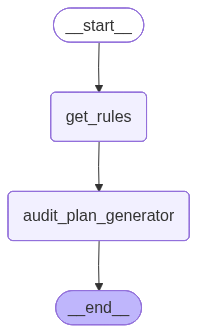

In [19]:
workflow


: 

: 

In [20]:
initial_state = {
    "standard" : "Schedule 3"
}


: 

: 

: 

In [21]:
workflow.invoke(initial_state)

req_sections=['Cover Page and Title', "Directors' Report", 'Statement of Financial Position (Balance Sheet)', 'Statement of Profit and Loss (Income Statement)', 'Statement of Cash Flows', 'Notes to Accounts – General Information and Accounting Policies', 'Notes – Share Capital and Reserves', 'Notes – Fixed Assets', 'Notes – Investments', 'Notes – Current Assets', 'Notes – Current Liabilities and Provisions', 'Notes – Contingent Liabilities and Commitments', "Auditor's Report"]


{'standard': 'Schedule 3',
 'necessary_sections': ['Cover Page and Title',
  "Directors' Report",
  'Statement of Financial Position (Balance Sheet)',
  'Statement of Profit and Loss (Income Statement)',
  'Statement of Cash Flows',
  'Notes to Accounts – General Information and Accounting Policies',
  'Notes – Share Capital and Reserves',
  'Notes – Fixed Assets',
  'Notes – Investments',
  'Notes – Current Assets',
  'Notes – Current Liabilities and Provisions',
  'Notes – Contingent Liabilities and Commitments',
  "Auditor's Report"],
 'audit_plan': ['Perform an overall compliance check of the document against Schedule 3 requirements, establishing scope and objectives for each listed section.',
  'Verify the Cover Page and Title contain all mandatory identifiers (company name, registration number, reporting period, and statement of compliance) and conform to prescribed format.',
  "Review the Directors' Report for completeness, including statutory disclosures, directors' declaration

: 

: 

: 

In [22]:
final_result = workflow.invoke(initial_state)


req_sections=['Balance Sheet (Statement of Financial Position)', 'Statement of Profit and Loss', 'Statement of Changes in Equity', 'Statement of Cash Flows', 'Notes to Accounts (including Accounting Policies, Share Capital, Reserves, Fixed Assets, Investments, Inventories, Loans and Advances, Current Liabilities, Provisions, etc.)', 'Schedule of Contingent Liabilities and Commitments']


: 

: 

: 

: 

In [23]:
final_result

{'standard': 'Schedule 3',
 'necessary_sections': ['Balance Sheet (Statement of Financial Position)',
  'Statement of Profit and Loss',
  'Statement of Changes in Equity',
  'Statement of Cash Flows',
  'Notes to Accounts (including Accounting Policies, Share Capital, Reserves, Fixed Assets, Investments, Inventories, Loans and Advances, Current Liabilities, Provisions, etc.)',
  'Schedule of Contingent Liabilities and Commitments'],
 'audit_plan': ["Obtain and review the entity's compliance checklist for Schedule III requirements to confirm coverage of all required financial statement components.",
  'Perform a preliminary risk assessment focusing on the Balance Sheet, Profit & Loss, Changes in Equity, Cash Flow Statement, Notes to Accounts, and Schedule of Contingent Liabilities and Commitments.',
  'Verify that the Balance Sheet (Statement of Financial Position) is presented in the prescribed format, including classification of current vs. non‑current assets and liabilities, and that

: 

: 

: 

: 

: 

: 

: 

In [ ]:
``

: 

: 

: 

: 

: 

: 

: 

: 

: 

In [ ]:
``

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 